# Comprobación de Modelos con Datos Medidos (Formato JSON)

Este notebook tiene como finalidad **validar y comprobar el funcionamiento de los modelos de detección de caídas** utilizando registros medidos directamente desde hardware real (almacenados en formato JSON).

### Diferencias y Enfoque respecto a `baseline_model.ipynb`:
1. **Carga de Datos mediante función JSON**:
   - En lugar de archivos sintéticos CSV (`FallAllD`), aquí se utiliza la función modular `extraer_datos_json()` para cargar las series temporales medidas en formato JSON (`datos_reales_editados`).
2. **Evaluación Diferenciada e Individual**:
   - **Acelerómetro Solo**: Red neuronal convolucional 1D (`modelo_acelerometro.keras`).
   - **Barómetro Solo**: Clasificador XGBoost (`modelo_barometro_xgboost.json`), omitiendo otros métodos para enfocarse en el modelo principal de presión.
3. **Fusión Ponderada Fija ($K = 0.3$)**:
   - En lugar de hacer barridos de métodos o parámetros, se aplica directamente la suma ponderada con $K = 0.3$ ($30\%$ barómetro, $70\%$ acelerómetro):
     $$P_{\text{fusión}} = K \cdot P_{\text{barómetro}} + (1 - K) \cdot P_{\text{acelerómetro}} = 0.3 \cdot P_{\text{barómetro}} + 0.7 \cdot P_{\text{acelerómetro}}$$
4. **Análisis Completo de Rendimiento para los Tres Casos**:
   - **Distribución de Densidad de Probabilidades**: Histogramas normalizados para evaluar la separación entre Caídas y No Caídas, junto con la Curva ROC y cálculo de AUC.
   - **Reporte de Clasificación Detallado**: Precision, Recall / Sensibilidad, F1-Score y Accuracy.
   - **Matriz de Confusión**: Presentación numérica y gráfica (heatmap anotado con conteos).


In [1]:
import os
import sys
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score

# Suprimir avisos innecesarios de TensorFlow
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf

# =============================================================================
# Configuración de rutas del proyecto
# =============================================================================
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'mediciones_centradas'
MODELS_DIR = PROJECT_ROOT / 'models'

from src.utils import (
    extraer_datos_json,
    calcular_altura,
    extraer_features,
    stats_perfom,
    matriz_confusion,
    graficar_distribucion_y_roc
)

print(f'Directorio de datos JSON:    {DATA_DIR}')
print(f'Directorio de modelos:       {MODELS_DIR}')


Directorio de datos JSON:    c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\data\processed\mediciones_centradas
Directorio de modelos:       c:\Users\guido\Documents\Paper - Deteccion de caidas\Fall_detection\models


In [2]:
# Función auxiliar para graficar una matriz de confusión en formato heatmap
def graficar_matriz_confusion_heatmap(tags, y_pred_bin, titulo="Matriz de Confusión"):
    cm = confusion_matrix(tags, y_pred_bin, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Pred: NO CAÍDA', 'Pred: CAÍDA'],
        yticklabels=['Real: NO CAÍDA', 'Real: CAÍDA'],
        annot_kws={"size": 13, "weight": "bold"}
    )
    plt.title(titulo, fontsize=12, pad=12)
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.tight_layout()
    plt.show()


## 1. Carga del Dataset Medido mediante `extraer_datos_json`

Se cargan los registros JSON de hardware mediante `extraer_datos_json`:
- **Acelerómetro**: Ejes `data_acel_x`, `data_acel_y`, `data_acel_z` (longitud 520 muestras a 40 Hz).
- **Barómetro**: Canales `press` y `temp` (longitud 130 muestras a 10 Hz).
- **Etiquetas**: Vector `tags` (1: Caída, 0: No Caída) y nombres de actividad `activity`.


In [3]:
# 1. Carga de series temporales de acelerómetro
data_acelerometro, tags, activity = extraer_datos_json(
    path=DATA_DIR,
    file='*.json',
    sensors='accelerometer'
)

# 2. Carga de series temporales de presión atmosférica y temperatura
data_presion, tags_presion, activity_presion = extraer_datos_json(
    path=DATA_DIR,
    file='*.json',
    sensors=['press', 'temp']
)

print(f'Total de registros medidos cargados: {len(tags)}')
print(f' - Caídas reales (1):    {np.sum(tags == 1)}')
print(f' - No Caídas reales (0): {np.sum(tags == 0)}')
print(f'Forma matriz acelerómetro: {data_acelerometro.shape}  -> (muestras, timesteps=520, sensores=3)')
print(f'Forma matriz barómetro:    {data_presion.shape}       -> (muestras, timesteps=130, canales=2)')


Total de registros medidos cargados: 116
 - Caídas reales (1):    57
 - No Caídas reales (0): 59
Forma matriz acelerómetro: (116, 520, 3)  -> (muestras, timesteps=520, sensores=3)
Forma matriz barómetro:    (116, 130, 2)       -> (muestras, timesteps=130, canales=2)


## 2. Preprocesamiento y Extracción de Features del Barómetro


In [4]:
# 1. Cálculo de la serie temporal de altitud relativa filtrada
alturas_mediciones = calcular_altura(data_presion, window_filter=20)

# 2. Extracción de las 12 características para el clasificador
features_extracted_presion = extraer_features(alturas_mediciones)

print(f"Dimensiones de alturas calculadas:     {alturas_mediciones.shape}")
print(f"Dimensiones de features para XGBoost: {features_extracted_presion.shape}")


Dimensiones de alturas calculadas:     (116, 111)
Dimensiones de features para XGBoost: (116, 12)


## 3. Carga de Modelos Pre-entrenados e Inferencia



In [5]:
# 1. Cargar modelo de acelerómetro
# NOTA
# "modelo_acelerometro.keras" uso datos de wrist y waist en su entrenamiento
# "modelo_acelerometro2.keras" uso datos de wrist en su entrenamiento

ruta_modelo_acc = MODELS_DIR / "modelo_acelerometro2.keras"
modelo_sensor_acelerometro = tf.keras.models.load_model(str(ruta_modelo_acc))

# 2. Cargar modelo de barómetro (XGBoost)
ruta_modelo_bar = MODELS_DIR / "modelo_barometro_xgboost.json"
modelo_sensor_presion = xgb.XGBClassifier()
modelo_sensor_presion.load_model(str(ruta_modelo_bar))

# 3. Inferencia de probabilidades
y_pred_acelerometro = modelo_sensor_acelerometro.predict(data_acelerometro, verbose=0)
y_pred_presion = modelo_sensor_presion.predict_proba(features_extracted_presion)[:, 1:2]

# 4. Fusión por suma ponderada con factor K = 0.3

print("Inferencia completada.")
print(f" - Predicciones acelerómetro: {y_pred_acelerometro.shape}")
print(f" - Predicciones barómetro:    {y_pred_presion.shape}")

K = 0.5
y_pred_fusion = (y_pred_presion * K) + (y_pred_acelerometro * (1.0 - K))



Inferencia completada.
 - Predicciones acelerómetro: (116, 1)
 - Predicciones barómetro:    (116, 1)


---
# Parte 1: Evaluación del Modelo de Acelerómetro Solo (CNN 1D)

Analizamos el comportamiento de la red convolucional sobre los datos de acelerómetro medidos en hardware.
- **Distribución de Densidad de Probabilidades y Curva ROC** (con cálculo de AUC).
- **Reporte de Clasificación y Matriz de Confusión**.


  MODELO 1: ACELERÓMETRO SOLO - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC


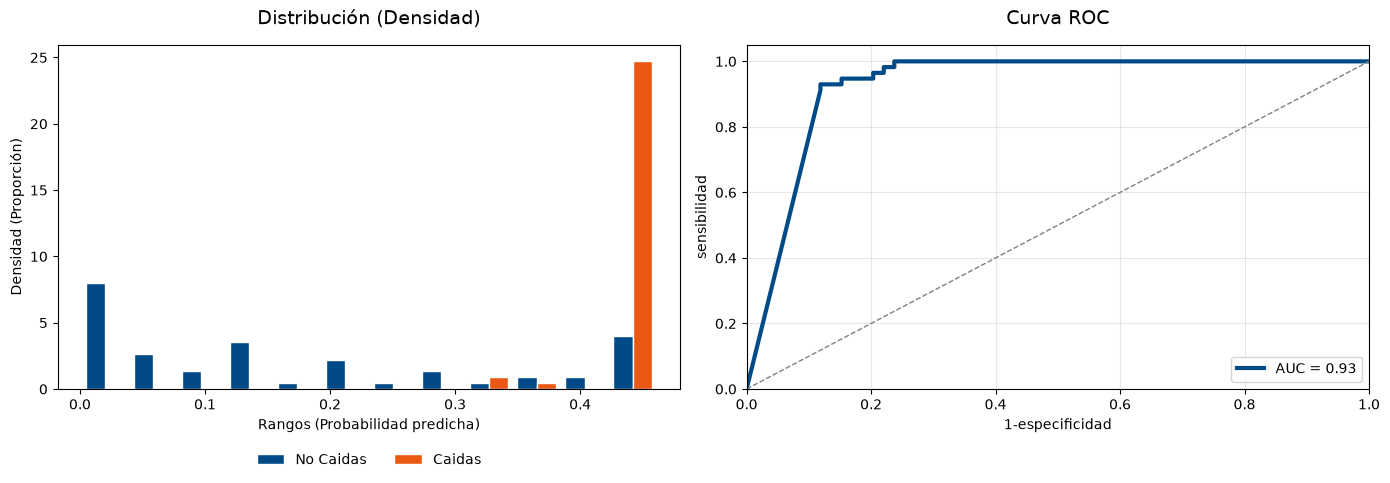

In [6]:
print("=" * 80)
print("  MODELO 1: ACELERÓMETRO SOLO - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC")
print("=" * 80)

graficar_distribucion_y_roc(tags, y_pred_acelerometro, bins=12)



=== REPORTE DE CLASIFICACIÓN - ACELERÓMETRO SOLO (Threshold = 0.4) ===
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.94      0.83      0.88        59
    FALL (1)       0.84      0.95      0.89        57

    accuracy                           0.89       116
   macro avg       0.89      0.89      0.89       116
weighted avg       0.89      0.89      0.89       116


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    49                 10
Real CAÍDA:       3                 54


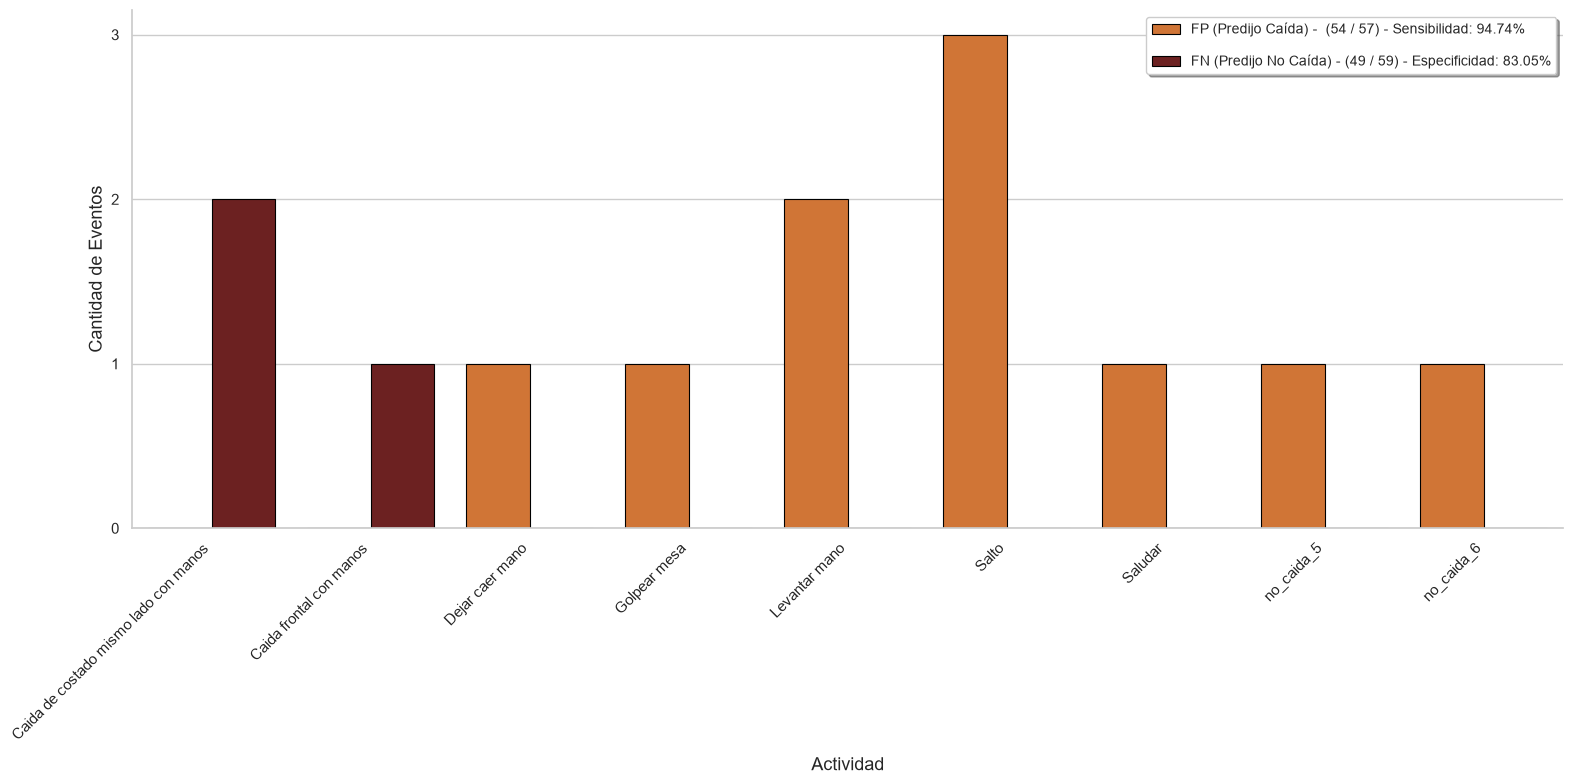

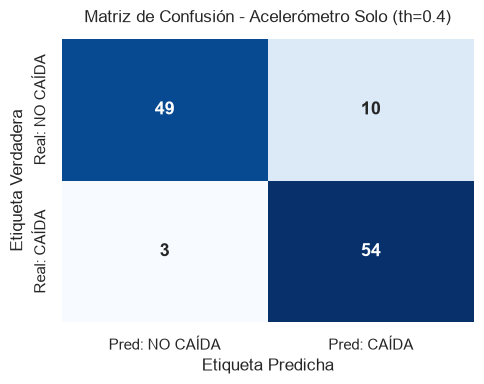

In [7]:
# Evaluación con el umbral óptimo identificado en baseline_model (th = 0.3)
threshold_acc = 0.4
y_pred_acc_bin = (y_pred_acelerometro > threshold_acc).astype(int)

print(f"\n=== REPORTE DE CLASIFICACIÓN - ACELERÓMETRO SOLO (Threshold = {threshold_acc}) ===")
stats_perfom(y_pred_acc_bin, tags, activity_names=activity)

graficar_matriz_confusion_heatmap(
    tags, y_pred_acc_bin,
    titulo=f"Matriz de Confusión - Acelerómetro Solo (th={threshold_acc})"
)


---
# Parte 2: Evaluación del Modelo de Barómetro Solo (XGBoost)

Evaluamos el desempeño del clasificador XGBoost utilizando únicamente las variaciones barométricas y térmicas convertidas en altitud.
- **Distribución de Densidad de Probabilidades y Curva ROC**.
- **Reporte de Clasificación y Matriz de Confusión**.


  MODELO 2: BARÓMETRO SOLO (XGBoost) - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC


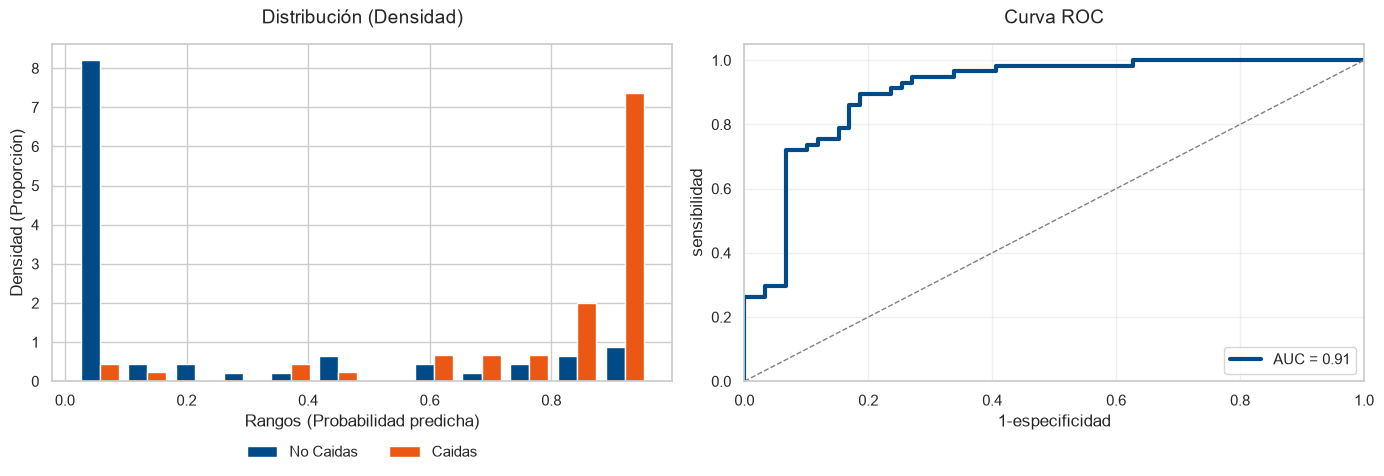

In [8]:
print("=" * 80)
print("  MODELO 2: BARÓMETRO SOLO (XGBoost) - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC")
print("=" * 80)

graficar_distribucion_y_roc(tags, y_pred_presion, bins=12)



=== REPORTE DE CLASIFICACIÓN - BARÓMETRO SOLO (XGBoost, Threshold = 0.5) ===
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.89      0.80      0.84        59
    FALL (1)       0.81      0.89      0.85        57

    accuracy                           0.84       116
   macro avg       0.85      0.85      0.84       116
weighted avg       0.85      0.84      0.84       116


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    47                 12
Real CAÍDA:       6                 51


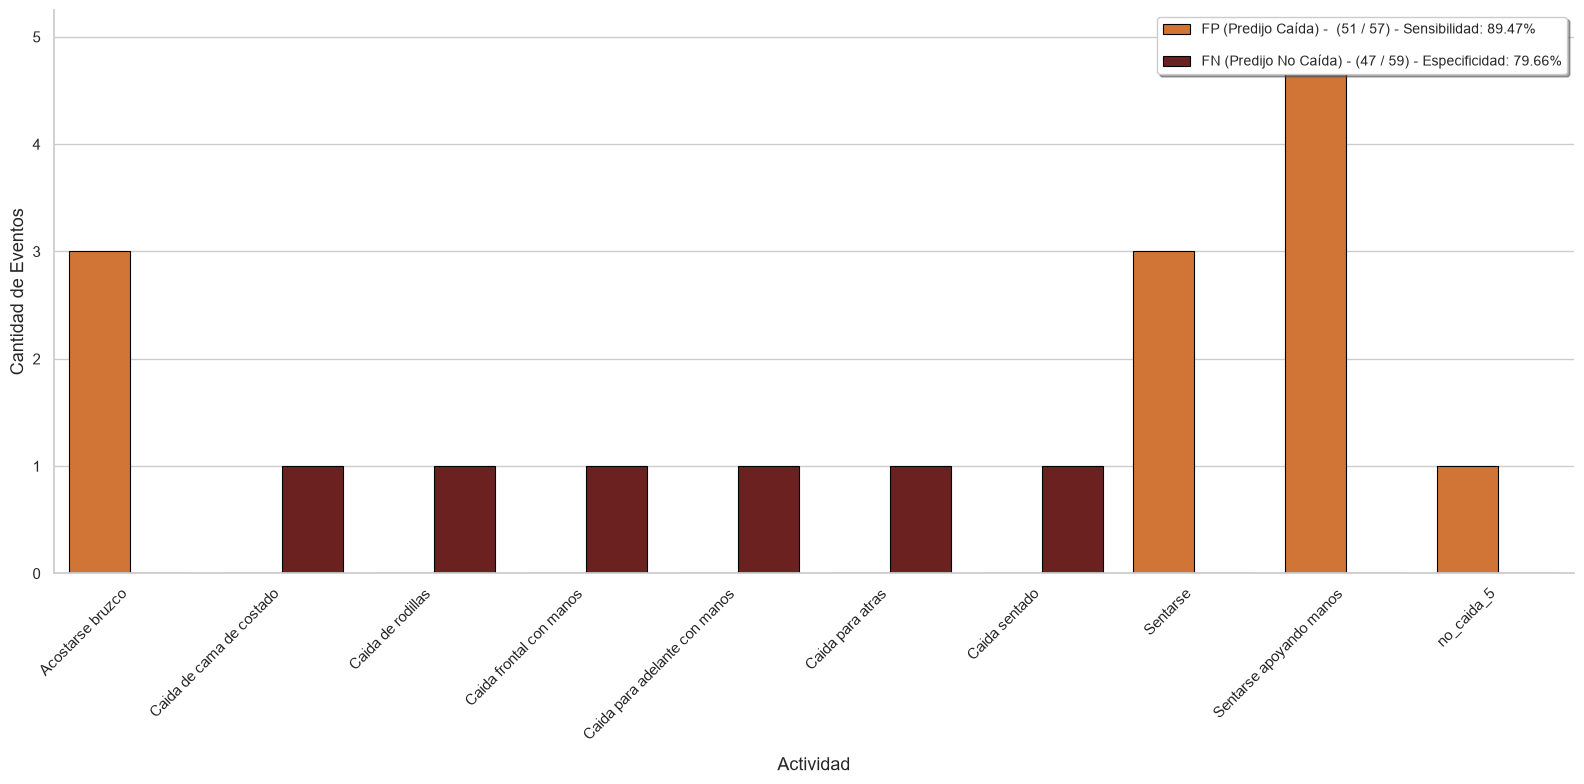

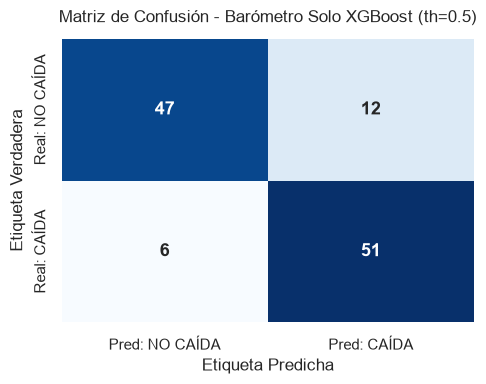

In [9]:
# Evaluación con umbral de decisión th = 0.5
threshold_bar = 0.5
y_pred_bar_bin = (y_pred_presion > threshold_bar).astype(int)

print(f"\n=== REPORTE DE CLASIFICACIÓN - BARÓMETRO SOLO (XGBoost, Threshold = {threshold_bar}) ===")
stats_perfom(y_pred_bar_bin, tags, activity_names=activity)

graficar_matriz_confusion_heatmap(
    tags, y_pred_bar_bin,
    titulo=f"Matriz de Confusión - Barómetro Solo XGBoost (th={threshold_bar})"
)


---
# Parte 3: Evaluación de la Fusión Ponderada ($K = 0.3$)

Evaluamos la combinación de ambos modelos mediante la suma ponderada:
$$P_{\text{fusión}} = 0.3 \cdot P_{\text{barómetro}} + 0.7 \cdot P_{\text{acelerómetro}}$$

Comprobamos:
- **Distribución de Densidad de Probabilidades y Curva ROC** de la probabilidad combinada.
- **Reporte de Clasificación y Matriz de Confusión** con umbral estándar ($th = 0.5$) y con umbral adaptado ($th = 0.35$).


  MODELO 3: FUSIÓN PONDERADA (K = 0.3) - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC


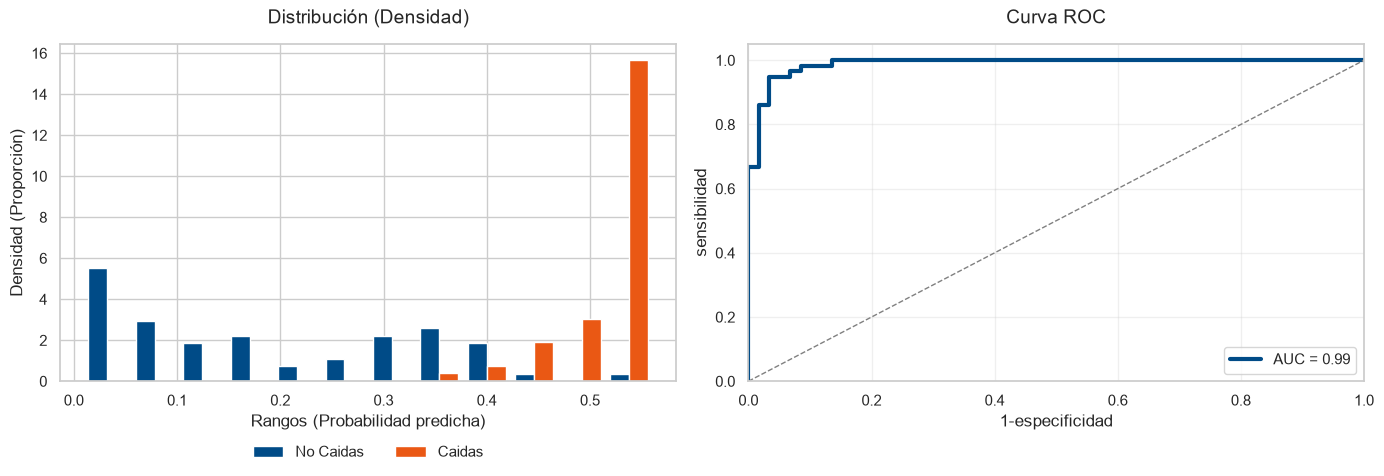

In [10]:
K = 0.2
y_pred_fusion = (y_pred_presion * K) + (y_pred_acelerometro * (1.0 - K))

print("=" * 80)
print("  MODELO 3: FUSIÓN PONDERADA (K = 0.3) - DISTRIBUCIÓN DE DENSIDAD Y CURVA ROC")
print("=" * 80)

graficar_distribucion_y_roc(tags, y_pred_fusion, bins=12)



=== REPORTE DE CLASIFICACIÓN - FUSIÓN PONDERADA (K=0.3, Threshold = 0.4) ===
=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

NOT FALL (0)       0.95      0.93      0.94        59
    FALL (1)       0.93      0.95      0.94        57

    accuracy                           0.94       116
   macro avg       0.94      0.94      0.94       116
weighted avg       0.94      0.94      0.94       116


=== MATRIZ DE CONFUSIÓN ===
                  Predice NO CAÍDA   Predice CAÍDA
Real NO CAÍDA:    55                 4
Real CAÍDA:       3                 54


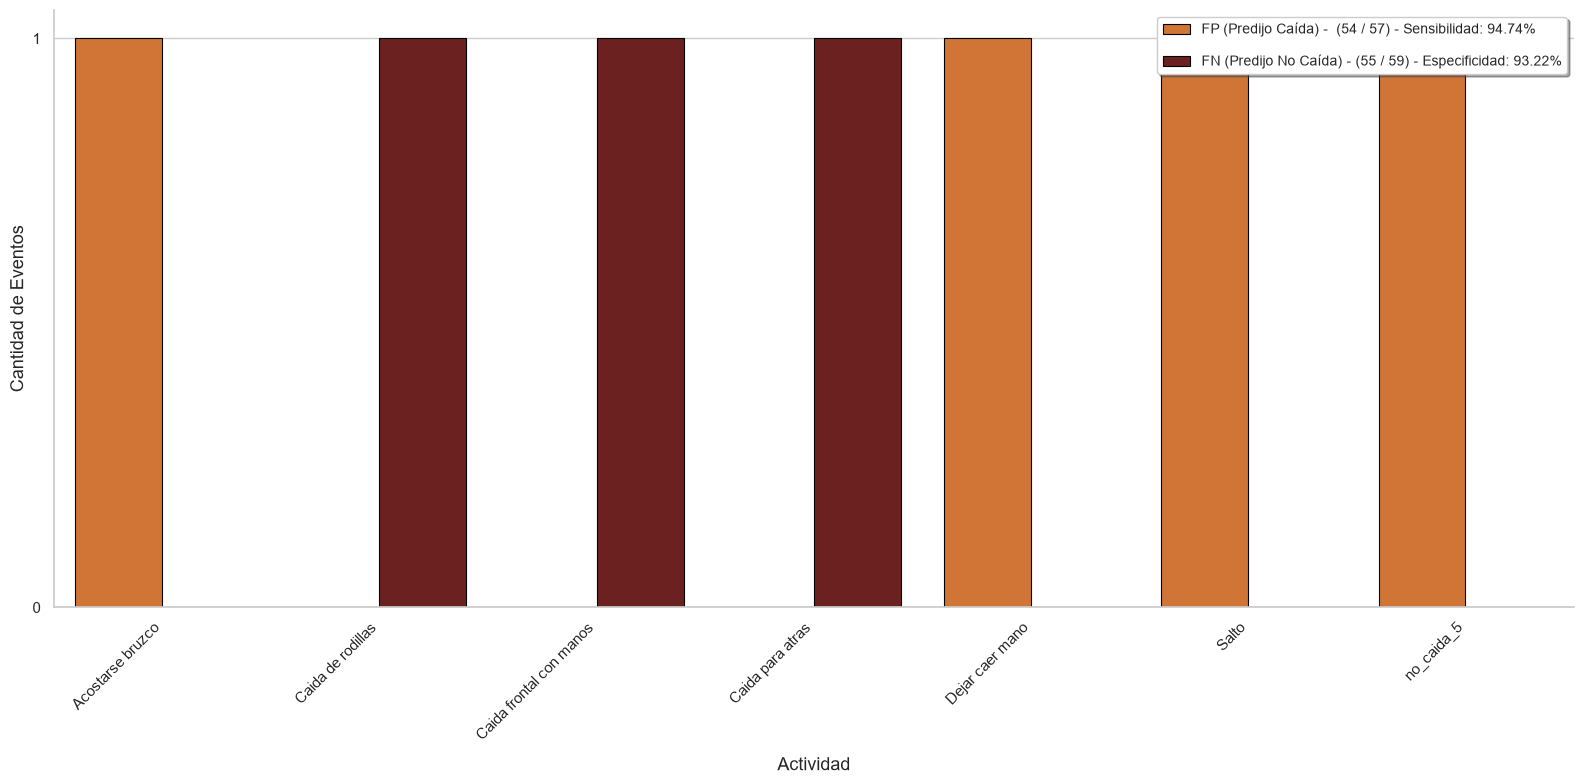

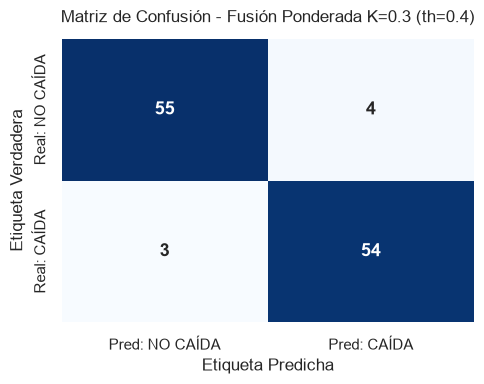

In [11]:
# Evaluación con umbral th = 0.5

threshold_fusion = 0.4
y_pred_fusion_bin = (y_pred_fusion > threshold_fusion).astype(int)

print(f"\n=== REPORTE DE CLASIFICACIÓN - FUSIÓN PONDERADA (K=0.3, Threshold = {threshold_fusion}) ===")
stats_perfom(y_pred_fusion_bin, tags, activity_names=activity)

graficar_matriz_confusion_heatmap(
    tags, y_pred_fusion_bin,
    titulo=f"Matriz de Confusión - Fusión Ponderada K=0.3 (th={threshold_fusion})"
)


---
# Parte 4: Comparativa Consolidada de los Tres Modelos

Sintetizamos las métricas clave de los tres casos evaluados sobre los registros medidos de hardware:
1. **Acelerómetro Solo**
2. **Barómetro Solo (XGBoost)**
3. **Fusión Ponderada ($K = 0.3$)**


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

modelos_resumen = [
    {
        "Modelo": "Acelerómetro Solo (th=0.4)",
        "Umbral": threshold_acc,
        "y_prob": y_pred_acelerometro.ravel(),
        "y_pred": y_pred_acc_bin.ravel()
    },

    {
        "Modelo": "Barómetro Solo XGBoost (th=0.5)",
        "Umbral": threshold_bar,
        "y_prob": y_pred_presion.ravel(),
        "y_pred": y_pred_bar_bin.ravel()
    },
    {
        "Modelo": "Fusión Ponderada K=0.2 (th=0.4)",
        "Umbral": threshold_fusion,
        "y_prob": y_pred_fusion.ravel(),
        "y_pred": y_pred_fusion_bin.ravel()
    },

]

resumen_filas = []
for m in modelos_resumen:
    tn, fp, fn, tp = confusion_matrix(tags, m["y_pred"]).ravel()
    especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    resumen_filas.append({
        "Configuración del Modelo": m["Modelo"],
        "Umbral": m["Umbral"],
        "Exactitud (Acc)": accuracy_score(tags, m["y_pred"]),
        "Sensibilidad (Recall)": recall_score(tags, m["y_pred"]),
        "Especificidad": especificidad,
        "Precisión": precision_score(tags, m["y_pred"], zero_division=0),
        "F1-Score": f1_score(tags, m["y_pred"], zero_division=0),
        "AUC-ROC": roc_auc_score(tags, m["y_prob"]),
        "VP": tp, "VN": tn, "FP": fp, "FN": fn
    })

df_comparativa = pd.DataFrame(resumen_filas)
try:
    styled_df = df_comparativa.style.format({
        "Exactitud (Acc)": "{:.3f}",
        "Sensibilidad (Recall)": "{:.3f}",
        "Especificidad": "{:.3f}",
        "Precisión": "{:.3f}",
        "F1-Score": "{:.3f}",
        "AUC-ROC": "{:.3f}"
    })
    try:
        styled_df = styled_df.background_gradient(subset=["Sensibilidad (Recall)", "Especificidad", "F1-Score", "AUC-ROC"], cmap="YlGn")
    except Exception:
        pass
    display(styled_df)
except Exception:
    display(df_comparativa)


,Configuración del Modelo,Umbral,Exactitud (Acc),Sensibilidad (Recall),Especificidad,Precisión,F1-Score,AUC-ROC,VP,VN,FP,FN
0,Acelerómetro Solo (th=0.4),0.4,0.887931,0.947368,0.830508,0.843750,0.892562,0.929527,54,49,10,3
1,Barómetro Solo XGBoost (th=0.5),0.5,0.844828,0.894737,0.796610,0.809524,0.850000,0.905144,51,47,12,6
2,Fusión Ponderada K=0.2 (th=0.4),0.4,0.939655,0.947368,0.932203,0.931034,0.939130,0.988701,54,55,4,3


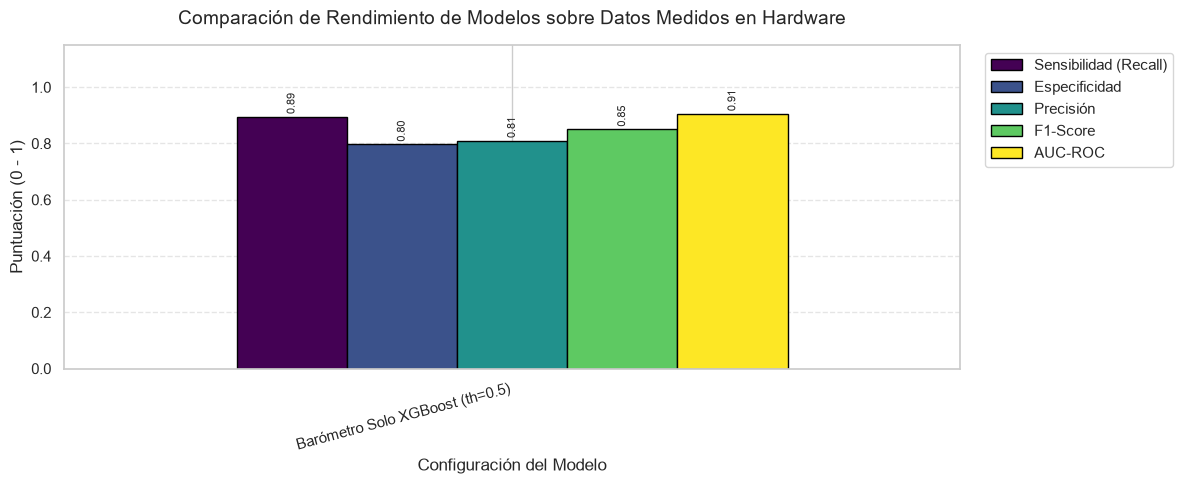

In [13]:
# Gráfico comparativo de barras entre las configuraciones principales
configs_principales = [
    "Acelerómetro Solo (th=0.3)",
    "Barómetro Solo XGBoost (th=0.5)",
    "Fusión Ponderada K=0.3 (th=0.4)",

]
df_plot = df_comparativa[df_comparativa["Configuración del Modelo"].isin(configs_principales)].set_index("Configuración del Modelo")
metricas_plot = ["Sensibilidad (Recall)", "Especificidad", "Precisión", "F1-Score", "AUC-ROC"]

ax = df_plot[metricas_plot].plot(
    kind="bar", figsize=(12, 5), width=0.8, colormap="viridis", edgecolor="black"
)
plt.title("Comparación de Rendimiento de Modelos sobre Datos Medidos en Hardware", fontsize=14, pad=15)
plt.ylabel("Puntuación (0 - 1)")
plt.ylim(0, 1.15)
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

for p in ax.patches:
    height = p.get_height()
    if height > 0.05:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, rotation=90, xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()


In [14]:
# Tabla de Auditoría Detallada Evento por Evento (para Caídas y Falsos Positivos)
df_auditoria = pd.DataFrame({
    'Archivo': activity,
    'Etiqueta Real': ['CAÍDA (1)' if t == 1 else 'NO CAÍDA (0)' for t in tags],
    'P_Acel': y_pred_acelerometro.ravel(),
    'P_Bar (XGB)': y_pred_presion.ravel(),
    'P_Fusión (K=0.3)': y_pred_fusion.ravel(),
    'Pred_Fusión_0.5': ['CAÍDA' if p >= 0.5 else 'NO CAÍDA' for p in y_pred_fusion.ravel()],
    'Acierto_0.5': ['CORRECTO' if ((p >= 0.5) == t) else 'ERROR' for p, t in zip(y_pred_fusion.ravel(), tags)]
})

print("=== EVENTOS DE CAÍDA REAL (10 Eventos) ===")
display(df_auditoria[tags == 1])

print("\n=== RESUMEN DE FALSOS POSITIVOS EN NO CAÍDA CON UMBRAL 0.5 ===")
display(df_auditoria[(tags == 0) & (df_auditoria['Acierto_0.5'] == 'ERROR')])


=== EVENTOS DE CAÍDA REAL (10 Eventos) ===


,Archivo,Etiqueta Real,P_Acel,P_Bar (XGB),P_Fusión (K=0.3),Pred_Fusión_0.5,Acierto_0.5
0,caida_2,CAÍDA (1),0.461037,0.919144,0.552658,CAÍDA,CORRECTO
1,caida_3,CAÍDA (1),0.461037,0.877899,0.544410,CAÍDA,CORRECTO
2,caida_4,CAÍDA (1),0.461037,0.930238,0.554878,CAÍDA,CORRECTO
3,caida_5,CAÍDA (1),0.461037,0.885787,0.545987,CAÍDA,CORRECTO
4,caida_7,CAÍDA (1),0.461037,0.818946,0.532619,CAÍDA,CORRECTO
5,caida_8,CAÍDA (1),0.461037,0.872655,0.543361,CAÍDA,CORRECTO
6,caida_9,CAÍDA (1),0.461037,0.905460,0.549922,CAÍDA,CORRECTO
7,caida_10,CAÍDA (1),0.461037,0.858290,0.540488,CAÍDA,CORRECTO
8,Caida para atras,CAÍDA (1),0.461037,0.955552,0.559940,CAÍDA,CORRECTO
9,Caida para atras,CAÍDA (1),0.461037,0.913617,0.551553,CAÍDA,CORRECTO



=== RESUMEN DE FALSOS POSITIVOS EN NO CAÍDA CON UMBRAL 0.5 ===


,Archivo,Etiqueta Real,P_Acel,P_Bar (XGB),P_Fusión (K=0.3),Pred_Fusión_0.5,Acierto_0.5
61,no_caida_5,NO CAÍDA (0),0.461037,0.830554,0.534941,CAÍDA,ERROR
